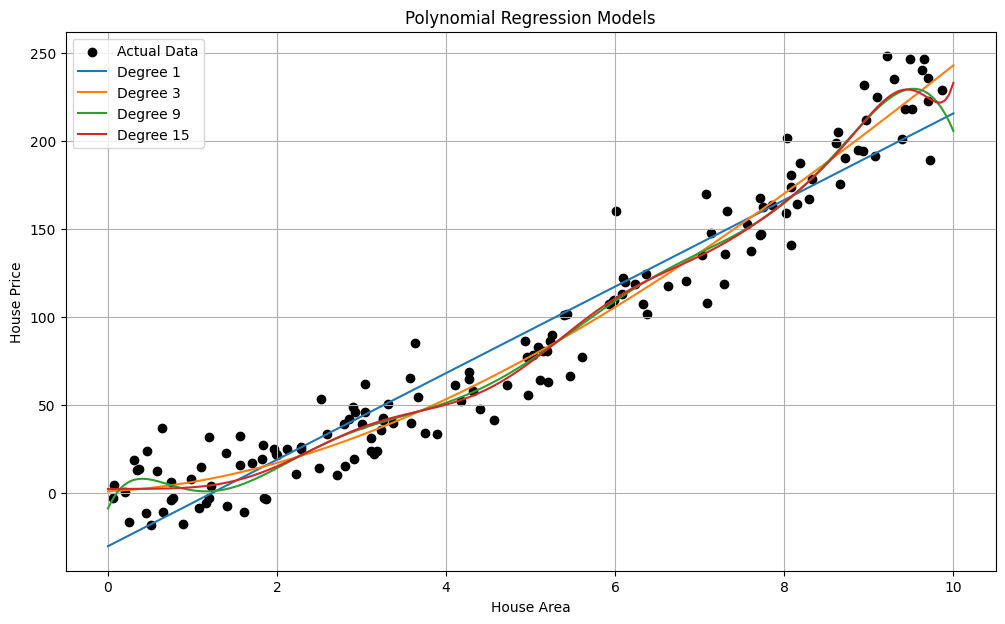

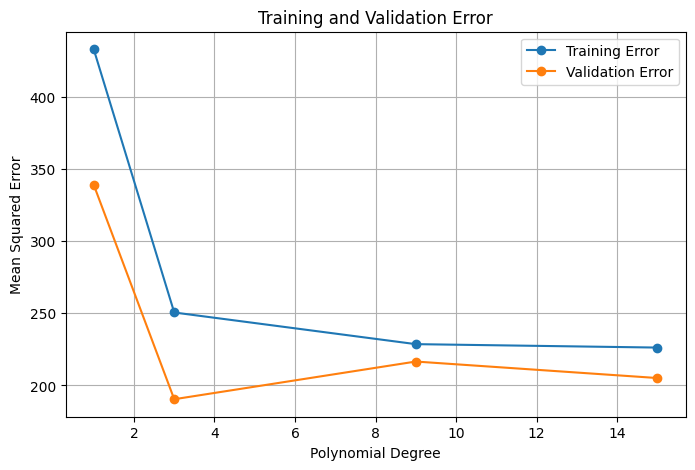

Estimated Bias Squared: 35.45384238298183
Estimated Variance: 10.595674368888627

Training Errors: [433.2482654864788, 250.60371685779575, 228.64338085095682, 226.26738331164583]
Validation Errors: [339.2143772007474, 190.43229722748055, 216.5768147708335, 205.13227786484038]
Best Polynomial Degree: 3


In [4]:

import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error

np.random.seed(42)

# Generate nonlinear house price dataset
X = np.sort(np.random.uniform(0, 10, 150)).reshape(-1, 1)
y = 5 * X.ravel() + 2 * X.ravel()**2 + np.random.normal(0, 15, 150)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42
)

degrees = [1, 3, 9, 15]
train_errors = []
test_errors = []

# Fit polynomial models
plt.figure(figsize=(12, 7))
plt.scatter(X, y, color="black", label="Actual Data")

x_plot = np.linspace(0, 10, 200).reshape(-1, 1)

for degree in degrees:
    model = make_pipeline(
        PolynomialFeatures(degree),
        LinearRegression()
    )

    model.fit(X_train, y_train)

    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)

    train_errors.append(
        mean_squared_error(y_train, train_pred)
    )

    test_errors.append(
        mean_squared_error(y_test, test_pred)
    )

    plt.plot(
        x_plot,
        model.predict(x_plot),
        label=f"Degree {degree}"
    )

plt.xlabel("House Area")
plt.ylabel("House Price")
plt.title("Polynomial Regression Models")
plt.legend()
plt.grid()
plt.show()

# Training and validation error
plt.figure(figsize=(8, 5))
plt.plot(degrees, train_errors, marker="o", label="Training Error")
plt.plot(degrees, test_errors, marker="o", label="Validation Error")
plt.xlabel("Polynomial Degree")
plt.ylabel("Mean Squared Error")
plt.title("Training and Validation Error")
plt.legend()
plt.grid()
plt.show()

# Bias-variance estimation using repeated resampling
predictions = []

for seed in range(30):
    X_sample, _, y_sample, _ = train_test_split(
        X, y, test_size=0.25, random_state=seed
    )

    model = make_pipeline(
        PolynomialFeatures(9),
        LinearRegression()
    )

    model.fit(X_sample, y_sample)
    predictions.append(model.predict(x_plot).ravel())

predictions = np.array(predictions)

mean_prediction = np.mean(predictions, axis=0)

variance = np.mean(np.var(predictions, axis=0))

true_function = 5 * x_plot.ravel() + 2 * x_plot.ravel()**2

bias_squared = np.mean(
    (mean_prediction - true_function)**2
)

print("Estimated Bias Squared:", bias_squared)
print("Estimated Variance:", variance)

# Best polynomial degree
best_degree = degrees[np.argmin(test_errors)]

print("\nTraining Errors:", train_errors)
print("Validation Errors:", test_errors)
print("Best Polynomial Degree:", best_degree)
